In [3]:
%load_ext autoreload
%autoreload 2

from kontext.visualization import get_figs,space_plot,space_plot_mask,get_proportions,plot_proportions,heatmap_proportions,plot_ccc_score_per_group,umap_plot,plot_ct_pair_across_samples,plot_region_distribution,pie_region
from utils.load_data import load_adata,load_and_preprocess_adata
from kontext.data import merge_adatas,preprocess_adata
from kontext.kontext_class import Kontext
from kontext.utils import local_alignment, get_LR_pairs, pca_of_mat,get_purity_vector_per_domain


from umap.umap_ import UMAP
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#fcf8f500'
plt.rcParams['axes.facecolor'] = '#fcf8f500'

from itables import init_notebook_mode
init_notebook_mode(all_interactive=True)



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
dataset = 'CARDIO'
samples = ['sham_S1','sham_S2',
            'cryo7D_S1','cryo7D_S2','cryo7D_S3',        
            'cryo28D_S1','cryo28D_S2','cryo28D_S3',
            ]


In [10]:
no_preprocessing = {'preprocessing':None}
preprocessing = {'preprocessing':'xenium'}
embedding = {"sigma_e":1, "snn":20, 'alpha':0.5}
spatial_domains = {'clustering':'gmm','seed':0,'n_domains':8}
niche,me,communication=True,True,True
# niche,me,communication=False,False,False



adatas = {}
for k in samples:
    print(k)
    adata = load_and_preprocess_adata({'dataset':'CARDIO','sample':k},preprocessing_params=no_preprocessing)
    adatas[k] = adata
adata_ = merge_adatas(adatas)
adata_.layers['counts'] = adata_.X
adata_ = preprocess_adata(adata_,**preprocessing)

adatas = {}
for k in samples:
    print(k)
    adata = adata_[adata_.obs['sample']==k].copy()
    adata.uns = adata_.uns.copy()
    adata.uns['data']['sample']=k
    ko = Kontext(**embedding,verbose=False)
    ko.weights(adata)
    ko.fit(adata,add_layer=True)
    ko.smooth_and_pca(adata, "wc", "C",add_layer=True)


    if niche:
        ko.niche(adata, cell_type_key="global_cell_type",verbose=False)
        ko.niche(adata, cell_type_key="cell_type",verbose=False)
    if me:
        ko.local_alignment(adata, layer_C="C")
    adatas[k] = adata 
adata_ = merge_adatas(adatas,block_diag_keys=['w','ws','wc','we'])

adata_.uns['data'] = {'dataset':'CARDIO','sample':'all','pp_str':'sparse_hvg_joint'}
ko = Kontext(**embedding,verbose=True)
print('spatial domains')
ko.spatial_domains_of_merged_adata(adata_,**spatial_domains)




sham_S1
sham_S2
cryo7D_S1
cryo7D_S2
cryo7D_S3
cryo28D_S1
cryo28D_S2
cryo28D_S3
sham_S1
sham_S2
cryo7D_S1
cryo7D_S2
cryo7D_S3
cryo28D_S1
cryo28D_S2
cryo28D_S3
spatial domains
pca of merged adata
spatial domains of merged adata
[Errno 2] No such file or directory: '/pasteur/appa/scratch/aozierla/CARDIO/all/sparse_hvg_joint/context/spatial_domains/snn20_se1_nPC50_a0.50_gmm_seed0_n_domains8.csv'
/pasteur/appa/scratch/aozierla/CARDIO/all/sparse_hvg_joint/context/spatial_domains/snn20_se1_nPC50_a0.50_gmm_seed0_n_domains8.csv
not loaded, computing spatial domains


In [11]:

spatial_domains_mapping = {
    3:0,
    1:1,
    2:2,
    4:6,
    0:7,
    7:4,
    5:3,
    6:5,}


adata_.obs['spatial_domains_sorted'] = adata_.obs['spatial_domains'].map(spatial_domains_mapping)
adata_.obs['spatial_domains_sorted'] = adata_.obs['spatial_domains_sorted'].astype('category').cat.set_categories(sorted(spatial_domains_mapping.keys()))


print(adata_.obs['main_cell_type'].nunique())
spatial_domains_colors = [
    "#4ad66d","#2A835F","#054a29","#56cfe1",
    "#7692FF","#6930c3","#ffcad4","#853953",]
spatial_domains_colors = [
    "#0072B2","#D55E00","#009E73","#CC79A7",
    "#E69F00","#56B4E9","#F0E442","#4E1A1A",]
cell_type_colors = [
    "#8DD3C7","#FFFFB3","#BEBADA","#FB8072",
    "#80B1D3","#FDB462","#B3DE69","#FCCDE5",
    "#D9D9D9","#BC80BD","#CCEBC5", "#FFED6F",
    "#DCD685","#D7AFAF",

    ]
time_colors = ["#d7b043","#BE4A4A","#006267",]

adata_.uns['spatial_domains_colors'] = spatial_domains_colors
adata_.uns['spatial_domains_sorted_colors'] = spatial_domains_colors
adata_.uns['main_cell_type_colors'] = cell_type_colors
adata_.uns['time_colors'] = time_colors


12


In [13]:
adata1s = {}
purity = {}
for cluster in adata_.obs['spatial_domains_sorted'].unique():
    # adata1 = adata_[adata_.obs['clustering'].isin(cluster)]

    adata1 = adata_[adata_.obs['spatial_domains_sorted']==cluster]
    for layer in 'XCE':
        print(layer, cluster,end=' ')
        mat = adata1.X if layer == 'X' else adata1.layers[layer]  if layer in 'CE' else adata1.obsm[f'niche_global_cell_type'] if layer == 'N' else adata1.obsm[f'niche_cell_type']
        print(mat.shape)
        n_comps = 10 if layer in 'NM' else 50
        pca_of_mat(adata1, mat, n_comps=n_comps, key=f"{layer}{cluster}")
        pca = adata1.obsm[f'{layer}{cluster}_pca']
        adata1.obsm[f'{layer}{cluster}_umap'] = UMAP(n_components=2).fit_transform(pca)


    # for layer in 'XCE':#EN':
        print('purity')
        ks, cp = get_purity_vector_per_domain(
            adata1.obsm[f'{layer}{cluster}_pca'],
            adata1.obs['time'].values,
            adata1.obs['clustering'].values,
        )
        purity[f'{layer}{cluster}'] = {'ks': ks, 'cluster_purities': cp}
    adata1s[f'{cluster}'] = adata1

X 7 (58973, 540)


/pasteur/helix/projects/ml4ig_hot/Users/aozierla/kontext/src/kontext/utils.py:327: ImplicitModificationWarning: Setting element `.obsm['X7_pca']` of view, initializing view as actual.


purity


KeyError: 'clustering'

NameError: name 'purity' is not defined

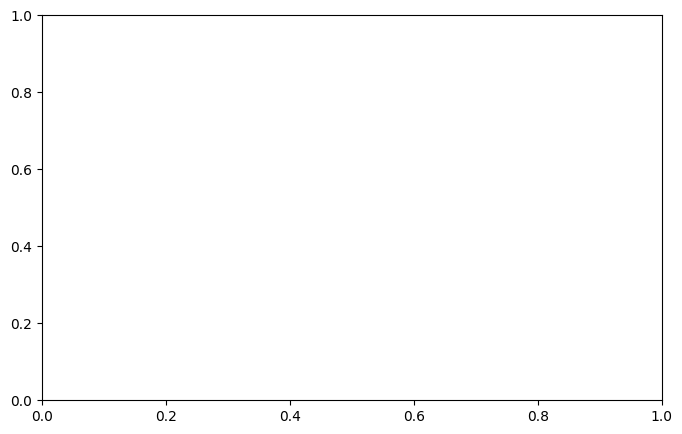

In [ ]:

from matplotlib.patches import Patch
layers = 'E'

# for i, layer in enumerate('XCEN'):
for i, layer in enumerate(layers):
    fig, ax = get_figs(1,8,5)
    # if isinstance(axes,np.ndarray):
    #     ax = axes[i]
    # else:
    #     ax = axes
    handles = []
    for domain in range(8):
        key = f'{layer}{domain}'
        if key in purity:
            ks = purity[key]['ks']
            # umap_plot(adata,color='time',umap_key=f'{layer}{name}_umap')
            arr = np.array(list(purity[key]['domain_purities'].values()))  # (n_domains, n_ks)
            mean = arr.mean(axis=0)
            # lo, hi = arr.min(axis=0), arr.max(axis=0)
            color = adata_.uns['spatial_domains_sorted_colors'][domain]
            ax.plot(ks, mean, color=color)
            handles.append(Patch(facecolor=color, label=f'SD{domain}'))
            # ax.fill_between(ks, lo, hi, alpha=0.2, color=color)
    # legend = ax.legend(fontsize=15,bbox_to_anchor=(1.05, 1),loc='upper left')
    legend = ax.legend(handles=handles, fontsize=20, bbox_to_anchor=(1.05, 1), loc='upper left')
    # For text in legend 
    # for text in legend: 
    #     change text color. 
    # ax.get_legend().remove()
    ax.set_ylim(0, 1)
    ax.set_title(f'Temporal concentration in {layer}',fontsize=15)
    ax.set_xticklabels(ax.get_xticklabels(), rotation='horizontal', fontsize=15) 
    ax.set_yticklabels(ax.get_yticklabels(), rotation='horizontal', fontsize=15) 
    ax.set_xlabel('$n$ neighbors',fontsize=15)
    ax.set_ylabel('Purity score',fontsize=15)
    fig.tight_layout()
    # fig.savefig(f'kontext_project/figures/cryo/cryo_2f_{layer}_purity.pdf',bbox_inches='tight')

In [ ]:
fig, axes = get_figs(2, 6, 5)

from kontext.utils import lr_normalize,lr_moments,lr_availability,lr_moments,lr_score,lr_aggregate,lr_cell_score,lr_log

mode = 'mean'
pairs = get_LR_pairs(adata_, organism='mouse', verbose=False)
lr_normalize(adata_, pairs)
lr_moments(adata_, 'X_lr')
lr_availability(adata_, None)
lr_moments(adata_, 'A_all')
# lr_moments(adata_, 'P_all')
lr_cell_score(adata_, 'all', mode=mode, col='LR_A_all',src='A')  
# lr_cell_score(adata_, 'all', mode=mode, col='LR_P_all',src='P')  

# adata_.obs[f'log_LR_all'] = lr_log(adata_.obs[f'LR_all'])
# print(adata_.obs[f'log_LR_all'])


ax = plot_ccc_score_per_group(adata_, 'spatial_domains_sorted', 'LR_A_all','sample','cryo7D_S1', ax=axes[0], insersion=(.10, .12))
# ax.axhline(1, ls='--', lw=.8, c='grey')
ax.set_title('Communication scores', fontsize=15); ax.set_ylabel('Mean per domain', fontsize=15); ax.set_xlabel(''); ax.set_yticks([])
ax.set_xticklabels([f'SD{t._text}' for t in ax.get_xticklabels()], rotation='horizontal', fontsize=15)
ax = plot_ccc_score_per_group(adata_, 'spatial_domains_sorted', 'local_alignment', 'sample','cryo7D_S1', ax=axes[1], insersion=(.10, .12))
ax.set_title('ME scores', fontsize=15); ax.set_ylabel(''); ax.set_xlabel(''); ax.set_yticks([])
ax.set_xticklabels([f'SD{t._text}' for t in ax.get_xticklabels()], rotation='horizontal', fontsize=15)
fig.tight_layout(); plt.show()

# fig, axes = get_figs(2, 6, 5)
# axes[0] = plot_ccc_score_per_group(adata_, 'spatial_domains_sorted', 'LR_P_all','sample','cryo7D_S1', ax=axes[0], insersion=(.10, .12))
# axes[1] = plot_ccc_score_per_group(adata_, 'spatial_domains_sorted', 'LR_A_all','sample','cryo7D_S1', ax=axes[1], insersion=(.10, .12))

#
# fig.savefig('kontext_project/figures/cryo/cryo_2e_communication_and_ME.png')

In [ ]:
import seaborn as sns
groups, ts, tr = 'main_cell_type', 'Fibroblast', 'Macrophage'
mode, samples_ = 'mean', ['sham_S1', 'cryo7D_S1', 'cryo28D_S1']
mode, times_ = 'mean', ['sham', 'cryo7D', 'cryo28D']  




mode = 'mean'
pairs = get_LR_pairs(adata_, organism='mouse', verbose=False)
lr_normalize(adata_, pairs)
lr_availability(adata_, None)
lr_moments(adata_, 'X_lr')
lr_moments(adata_, 'A_all')
lr_cell_score(adata_, 'all', mode=mode, col='LR_all')  
lr_moments(adata_, 'P_all')



ts, tr = 'Fibroblast', 'Macrophage'
for tx,tc in (ts, tr),(tr,ts),(ts, ts), (tr, tr): 
    # lr_moments(adata_, f'A_{tc}', om=((adata_.obs[f'm_{tc}'] > 0) & (adata_.obs['main_cell_type']==tx) ).values,r=r)
    lr_availability(adata_, tx, groups)
    lr_availability(adata_, tc, groups)
    r = {'col':groups,'value':tx}
    lr_moments(adata_, 'X_lr',r=r)
    lr_moments(adata_, f'A_{tc}', om=(adata_.obs[f'm_{tc}'] > 0).values,r=r)
    lr_moments(adata_, f'P_{tc}', om=(adata_.obs[f'm_{tc}'] > 0).values,r=r)


In [ ]:
genes = [
    'Cfh_Itgam','C3_Itgam','C3_C3ar1',

    'Ccl12_Ccr2','Spp1_Cd44','Mmp9_Cd44','Ptn_Sdc1',

    'Thbs4_Cd36','Thbs4_Sdc1','Comp_Sdc1',

    'Bmp7_Eng',

    'Timp3_Cd44','S100a4_Erbb2',

    'Timp3_Kdr','Angpt2_Tie1',
]

send_groups = [
    [(ts, tr), (tr, tr)],   # plot 1: both senders → Macrophage
    [(tr, ts), (ts, ts)],   # plot 2: both senders → Fibroblast
]

top=15
fig, axes = get_figs(len(send_groups), 12, 6)   # 2 wider plots

for i, (ax, pair_list) in enumerate(zip(axes, send_groups)):
    parts, senders = [], []
    for (s_, r_) in pair_list:
        r = {'col': groups, 'value': r_}
        S = lr_score(adata_, s_, r_, groups, mode, r=r,src='P')

        gi = pd.Index(adata_.uns['lr']['genes'])
        pos = adata_.obs_names.get_indexer(S.index)
        det = pd.Series(np.asarray((adata_.obsm['X_lr'][pos][:, gi.get_indexer(pairs.receptor)] > 0).mean(0)).ravel(), index=pairs.index)
        keep = det[det > .1].index
        T = lr_aggregate(adata_, S, s_, by='time')['all'].reindex(times_)[[g for g in genes if g in keep and g in S.columns]]

        parts.append((lr_log(T) if mode == 'mean' else T).T)
        senders.append(s_)

    merged = pd.concat(parts, axis=1)   # <-- horizontal concat: 6 columns

    label = 'Sender-receiver score' if i == 1 else ''
    cbar = (i == 1)
    print(merged)
    hm = sns.heatmap(merged, ax=ax, cmap='RdBu_r', center=0, vmin=-6, vmax=4,
                annot=True, fmt='.2f', annot_kws={'fontsize':15},
                linewidths=.5, cbar=cbar, cbar_kws={'label': label})
    if cbar:
        cbar_ax = hm.collections[0].colorbar
        cbar_ax.set_label(cbar_ax.ax.get_ylabel(), fontsize=fs)

    ax.axvline(len(parts[0].columns), color='white', lw=12)   # separator between the 2 senders

    # sender names above the time labels (optional)
    sec = ax.secondary_xaxis('top')
    sec.set_xticks([1.5, len(parts[0].columns) + 1.5])
    sec.set_xticklabels([f'{s} sender' for s in senders], fontsize=25)
    sec.tick_params(length=0)

    ax.set_title(f'{pair_list[0][1]} receiver', fontsize=25)
    ax.set_xlabel('')
    if i == 0:
        ax.set_ylabel('LR pair', fontsize=25)
    else:
        ax.set_ylabel('')
    ax.set_yticklabels(ax.get_yticklabels(), rotation='horizontal', fontsize=20)
    ax.set_xticklabels(ax.get_xticklabels(), rotation='vertical', fontsize=20)

fig.tight_layout()
plt.show()

# fig.savefig('kontext_project/figures/cryo/cryo_2g_FB_macro_communication.pdf')



In [ ]:
color = "spatial_domains_sorted"
domains = adata_.obs[color].sort_values().unique()


for sample in samples:
    ncols=len(domains)
    adata = adata_[adata_.obs['sample']==sample]

#1  : comme dans le main 
    # groups = [0,1,2,6],[3,4,5,7]
    # for i,group in enumerate(groups):
    #     fig,axes = get_figs(4,4,5)
    #     for ax,domain in zip(axes,group):

#2 : une ligne par sample 
    fig,axes = get_figs(8,4,5)
    for domain,ax in zip(range(8),axes):
        for _ in [0]:
#            

            if domain == 8:
                ax.set_axis_off()
                continue
            for spine in ax.spines.values():
                spine.set_visible(False)
            mask = space_plot_mask(adata,color,domain,ax=ax,snm=5,sm=50)
            ax.set_title('',fontsize=20)        
            ax.set_xlabel(f"SD{domain}",fontsize=40,color=adata.uns[f'{color}_colors'][domain])
            ax.set_ylabel("")
            ax.get_legend().remove()

        fig.tight_layout()
        gap = 0.05  
        for ax in axes[:3]:  
            p = ax.get_position()
            ax.set_position([p.x0 - gap/2, p.y0, p.width, p.height])
        for ax in axes[6:]:   
            p = ax.get_position()
            ax.set_position([p.x0 + gap/2, p.y0, p.width, p.height])


    plt.show()
# sample.replace('_S','').replace('sham','0D').replace('cryo','')} 
# fig.savefig('kontext_project/figures/cryo/cryo_supp_space_plot_spatial_domains.pdf')

In [ ]:


cols = (['sample','main_cell_type'],)#,['time','main_cell_type'])#['sample','global_cell_type'])
fig,axes = get_figs(8,4,5)
for domain in range(8):
        ax = axes[domain]
        adata = adata_[adata_.obs['spatial_domains_sorted']==domain]
        for col1,col2 in cols:

            # fig,axes = get_figs(1,6,5)
            proportions2 = get_proportions(adata,col1,col2,normalize='index')
            proportions2 = get_proportions(adata,col1,col2,normalize=False)
            ax.set_title(f'domain {domain}')
            plot_proportions(proportions2,ax=ax,colors =adata_.uns[f'{col2}_colors'])
            ax.set_title(f'SD{domain} over time',fontsize=fs,color=adata_.uns[f'spatial_domains_sorted_colors'][domain])

            
            # ax.set_yticklabels(ax.get_yticklabels() if domain == 0 else [], rotation='horizontal', fontsize=fs) 
            ax.set_yticklabels([tick._text.replace('_S','').replace('cryo','')#.replace('sham','0D') 
                                for tick in ax.get_yticklabels()] if domain == 0 else [], rotation='horizontal', fontsize=fs) 


            # ax.set_xticklabels([f'{int(tick._text)/1000:g}k' for tick in ax.get_xticklabels()], rotation='horizontal', fontsize=12) 
            xmin, xmax = ax.get_xlim()
            step = 10000 if xmax > 20000 else 2000 if xmax > 3000 else 1000
            ticks = np.arange(np.ceil(xmin / step) * step, xmax + 1, step)
            ax.set_xticks(ticks)
            ax.set_xticklabels([f'{t/1000:g}k' for t in ticks] if xmax>20000 else [f'{int(t)}' for t in ticks],fontsize=fs)
            # ax.set_xticklabels(,fontsize=fs)


            ax.set_xlabel('$n_{obs}$',fontsize=fs)
            ax.set_ylabel('',fontsize=fs)
            # legend = ax.legend(fontsize=15,bbox_to_anchor=(1.05, 1),loc='upper left')
            ax.get_legend().remove()



fig.tight_layout()
gap = 0.05  
for ax in axes[:3]:  
    p = ax.get_position()
    ax.set_position([p.x0 - gap/2, p.y0, p.width, p.height])
for ax in axes[6:]:   
    p = ax.get_position()
    ax.set_position([p.x0 + gap/2, p.y0, p.width, p.height])



In [ ]:
layer = 'E'
fig,axes = get_figs(8,4,5)


for domain in adata_.obs['spatial_domains_sorted'].unique():
    # adata1 = adata_[adata_.obs['spatial_domains'].isin(domain)]
    ax = axes[domain]
    adata1 = adata1s[f'{domain}']
    umap_plot(adata1,color='time',ax=ax,umap_key=f'{layer}{domain}_umap')
    ax.set_title(f'SD{domain}',fontsize=fs,color=adata_.uns[f'spatial_domains_sorted_colors'][domain])
    if domain != 7:
        ax.get_legend().remove()
    else:
        leg = ax.get_legend()                      # legend created by umap_plot
        handles = [Patch(facecolor=np.atleast_2d(h.get_facecolor())[0],
                         label=t.get_text())
                   for h, t in zip(leg.legend_handles, leg.get_texts())]
        ax.legend(handles=handles, fontsize=fs, bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.set_ylabel('E umap' if domain == 0 else '',fontsize=fs)
    ax.set_xlabel('')
fig.tight_layout()
gap = 0.05  
for ax in axes[:3]:  
    p = ax.get_position()
    ax.set_position([p.x0 - gap/2, p.y0, p.width, p.height])
for ax in axes[6:]:   
    p = ax.get_position()
    ax.set_position([p.x0 + gap/2, p.y0, p.width, p.height])



In [ ]:
from matplotlib.patches import Patch
layers = 'XC'


fig,axes = get_figs(2,6,5)

# for i, layer in enumerate('XCEN'):
for i, layer in enumerate(layers):
    ax = axes[i]
    # if isinstance(axes,np.ndarray):
    #     ax = axes[i]
    # else:
    #     ax = axes
    handles = []
    for domain in range(8):
        key = f'{layer}{domain}'
        if key in purity:
            ks = purity[key]['ks']
            # umap_plot(adata,color='time',umap_key=f'{layer}{name}_umap')
            arr = np.array(list(purity[key]['domain_purities'].values()))  # (n_domains, n_ks)
            mean = arr.mean(axis=0)
            # lo, hi = arr.min(axis=0), arr.max(axis=0)
            color = adata_.uns['spatial_domains_sorted_colors'][domain]
            ax.plot(ks, mean, color=color)
            handles.append(Patch(facecolor=color, label=f'SD{domain}'))
            # ax.fill_between(ks, lo, hi, alpha=0.2, color=color)
    # legend = ax.legend(fontsize=15,bbox_to_anchor=(1.05, 1),loc='upper left')
    if i == 1 :
        legend = ax.legend(handles=handles, fontsize=20, bbox_to_anchor=(1.05, 1), loc='upper left')
    # For text in legend 
    # for text in legend: 
    #     change text color. 
    # ax.get_legend().remove()
    ax.set_ylim(0, 1)
    ax.set_title(f'Temporal concentration in {layer}',fontsize=15)

    ax.set_xticklabels(ax.get_xticklabels(), rotation='horizontal', fontsize=15) 

    ax.set_yticklabels(ax.get_yticklabels()if i == 0 else [], rotation='horizontal', fontsize=15) 
    ax.set_xlabel('$n$ neighbors',fontsize=15)
    ax.set_ylabel('Purity score' if i==0 else '',fontsize=15)
    fig.tight_layout()
    # fig.savefig(f'kontext_project/figures/cryo/cryo_2f_{layer}_purity.pdf',bbox_inches='tight')

In [ ]:
import seaborn as sns
groups, ts, tr = 'main_cell_type', 'Fibroblast', 'Macrophage'
mode, samples_ = 'mean', ['sham_S1', 'cryo7D_S1', 'cryo28D_S1']
mode, times_ = 'mean', ['sham', 'cryo7D', 'cryo28D']  




mode = 'mean'
pairs = get_LR_pairs(adata_, organism='mouse', verbose=False)
lr_normalize(adata_, pairs)
lr_availability(adata_, None)
lr_moments(adata_, 'X_lr')
lr_moments(adata_, 'A_all')
lr_cell_score(adata_, 'all', mode=mode, col='LR_all')  
lr_moments(adata_, 'P_all')



ts, tr = 'Fibroblast', 'Macrophage'
for tx,tc in (ts, tr),(tr,ts),(ts, ts), (tr, tr): 
    # lr_moments(adata_, f'A_{tc}', om=((adata_.obs[f'm_{tc}'] > 0) & (adata_.obs['main_cell_type']==tx) ).values,r=r)
    lr_availability(adata_, tx, groups)
    lr_availability(adata_, tc, groups)
    r = {'col':groups,'value':tx}
    lr_moments(adata_, 'X_lr',r=r)
    lr_moments(adata_, f'A_{tc}', om=(adata_.obs[f'm_{tc}'] > 0).values,r=r)
    lr_moments(adata_, f'P_{tc}', om=(adata_.obs[f'm_{tc}'] > 0).values,r=r)

In [ ]:
send_groups = [
    [(ts, tr), (tr, tr)],   # plot 1: both senders → Macrophage
    [(tr, ts), (ts, ts)],   # plot 2: both senders → Fibroblast
]




for aggregate_by,order in zip(['time','sample','spatial_domains_sorted'],[times_,samples,[f'{i}' for i in range(8)]]):
# for aggregate_by,order in zip(['spatial_domains_sorted'],[[f'{i}' for i in range(8)]]):
    print(order)
    fig, axes = get_figs(len(send_groups), 15, 10)   # 2 wider plots
    genes = adata_.uns['lr']['pairs']['LR']
    # print(genes)
    for i, (ax, pair_list) in enumerate(zip(axes, send_groups)):
        parts, senders = [], []
        for (s_, r_) in pair_list:
            r = {'col': groups, 'value': r_}
            S = lr_score(adata_, s_, r_, groups, mode, r=r,src='P')
            # print(S)
            gi = pd.Index(adata_.uns['lr']['genes'])
            pos = adata_.obs_names.get_indexer(S.index)
            det = pd.Series(np.asarray((adata_.obsm['X_lr'][pos][:, gi.get_indexer(pairs.receptor)] > 0).mean(0)).ravel(), index=pairs.index)
            keep = det[det > .1].index
            T = lr_aggregate(adata_, S, s_, by=aggregate_by)['all'].reindex(order)[[g for g in genes if g in keep and g in S.columns]]
            parts.append((lr_log(T) if mode == 'mean' else T).T)
            senders.append(s_)

        merged = pd.concat(parts, axis=1)   # <-- horizontal concat: 6 columns

        label = 'Sender-receiver score' if i == 1 else ''
        cbar = (i == 1)
        print(merged)
        hm = sns.heatmap(merged, ax=ax, cmap='RdBu_r', center=0, vmin=-6, vmax=4,
                    annot=True, fmt='.2f', annot_kws={'fontsize':15},
                    linewidths=.5, cbar=cbar, cbar_kws={'label': label})
        if cbar:
            cbar_ax = hm.collections[0].colorbar
            cbar_ax.set_label(cbar_ax.ax.get_ylabel(), fontsize=fs)

        ax.axvline(len(parts[0].columns), color='white', lw=12)   # separator between the 2 senders

        # sender names above the time labels (optional)
        sec = ax.secondary_xaxis('top')
        sec.set_xticks([1.5, len(parts[0].columns) + 1.5])
        sec.set_xticklabels([f'{s} to {pair_list[0][1]}' for s in senders], fontsize=25)
        sec.tick_params(length=0)

        ax.set_title(f'{pair_list[0][1]} receiver', fontsize=25)
        ax.set_xlabel('')
        if i == 0:
            ax.set_ylabel('LR pair', fontsize=25)
        else:
            ax.set_ylabel('')
        ax.set_yticklabels(ax.get_yticklabels(), rotation='horizontal', fontsize=20)
        ax.set_xticklabels(ax.get_xticklabels(), rotation='vertical', fontsize=20)

    fig.tight_layout()
    plt.show()

# fig.savefig('kontext_project/figures/cryo/cryo_2g_FB_macro_communication.pdf')



In [2]:

print(ts,tr)
fig, axes = get_figs(2, 5, 5)
for ax, t in zip(axes, [ts, tr]): pie_region(adata_, t, f'sample', 'main_cell_type', ax=ax)
fig, axes = get_figs(2, 5, 5)
for ax, t in zip(axes, [ts, tr]): pie_region(adata_, t, f'time', 'main_cell_type', ax=ax)
fig, axes = get_figs(2, 5, 5)
for ax, t in zip(axes, [ts, tr]): pie_region(adata_, t, f'spatial_domains', 'main_cell_type', ax=ax)

NameError: name 'ts' is not defined

In [132]:

adata_
pca_of_mat(adata_,adata_.X,n_comps=50,key='X')
adata_.obsm[f'X_umap'] = UMAP(n_components=2).fit_transform(adata_.obsm['X_pca'])
print('C_umap')
adata_.obsm[f'C_umap'] = UMAP(n_components=2).fit_transform(adata_.obsm['C_pca'])
print('E_umap')
adata_.obsm[f'E_umap'] = UMAP(n_components=2).fit_transform(adata_.obsm['E_pca'])


In [133]:
for layer in 'XCE':
    fig,axes = get_figs(4,4,5)
    for i,col in enumerate(['main_cell_type', 'spatial_domains_sorted', 'sample', 'time']):
        ax = axes[i]
        umap_plot(adata_,col,umap_key=f'{layer}_umap',ax=ax,s=.5)
        ax.get_legend().remove()
    


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.sparse as sps
def lr_pair_descriptors(adata, sender, receiver, region_key, pairs,
                        groups='main_cell_type', src='P'):
    obs = adata.obs
    gi = pd.Index(adata.uns['lr']['genes'])
    X = adata.obsm['X_lr']
    is_sparse = sps.issparse(X)

    m = obs[f'm_{sender}']
    S = lr_score(adata, sender, receiver, groups, mode='mean', src=src)

    rec_mask = obs[groups] == receiver
    snd_mask = obs[groups] == sender
    regions = obs[region_key].astype(str).unique()

    lig_idx = gi.get_indexer(pairs.ligand)
    rec_idx = gi.get_indexer(pairs.receptor)
    missing_lig = lig_idx == -1
    missing_rec = rec_idx == -1

    desc = {}
    for region in regions:
        reg_mask = obs[region_key] == region

        # intersect with S.index so .loc never fails
        rec_cells = obs.index[reg_mask & rec_mask].intersection(S.index)
        snd_cells = obs.index[reg_mask & snd_mask]

        n_rec = len(rec_cells)
        n_snd = len(snd_cells)

        # scalar descriptors use the cells that are actually in S
        sender_context = m.loc[rec_cells].mean() if n_rec > 0 else np.nan
        receiver_with_sender = (m.loc[rec_cells] > 0).mean() if n_rec > 0 else np.nan

        n_pairs = len(pairs)
        receptor_prev = np.full(n_pairs, np.nan, dtype=np.float32)
        ligand_sender = np.full(n_pairs, np.nan, dtype=np.float32)

        if n_rec > 0:
            rec_expr = X[obs.index.get_indexer(rec_cells)][:, rec_idx]
            if is_sparse:
                receptor_prev[:] = rec_expr.getnnz(axis=0) / n_rec
            else:
                receptor_prev[:] = (rec_expr > 0).mean(axis=0)

        if n_snd > 0:
            lig_expr = X[obs.index.get_indexer(snd_cells)][:, lig_idx]
            if is_sparse:
                ligand_sender[:] = np.asarray(lig_expr.mean(axis=0)).ravel()
            else:
                ligand_sender[:] = lig_expr.mean(axis=0)

        receptor_prev[missing_rec] = np.nan
        ligand_sender[missing_lig] = np.nan

        if n_rec > 0:
            S_reg = S.loc[rec_cells]
            mean_score = S_reg.mean(axis=0).values
            prevalence = (S_reg > 0).mean(axis=0).values
        else:
            mean_score = np.full(n_pairs, np.nan)
            prevalence = np.full(n_pairs, np.nan)

        df = pd.DataFrame({
            'sender_context': sender_context,
            'receiver_with_sender': receiver_with_sender,
            'receptor_prev': receptor_prev,
            'ligand_sender': ligand_sender,
            'mean_score': mean_score,
            'prevalence': prevalence,
        }, index=pairs.index)
        desc[region] = df

    return desc

def plot_lr_descriptor_heatmaps(desc, cmap='viridis', figsize=None,
                                annot=True, fmt='.2f'):
    """
    Plot one heatmap per region. Rows = LR pairs, columns = descriptors.
    Each descriptor column is min-max normalized independently.
    """
    regions = list(desc.keys())
    n = len(regions)
    fig, axes = plt.subplots(1, n, figsize=figsize or (6 * n, 8))
    if n == 1:
        axes = [axes]

    for ax, region in zip(axes, regions):
        df = desc[region]

        # column-wise min-max normalization (each descriptor gets its own scale)
        df_norm = df.apply(
            lambda x: (x - x.min()) / (x.max() - x.min())
            if x.max() != x.min() else 0.5
        )

        sns.heatmap(
            df_norm.T if False else df_norm,   # rows=LR pairs, cols=descriptors
            ax=ax,
            cmap=cmap,
            vmin=0, vmax=1,
            annot=annot,
            fmt=fmt,
            annot_kws={'size': 8},
            cbar_kws={'label': 'column-normalized'},
        )
        ax.set_title(f'{sender} → {receiver}\n{region}', fontsize=14)
        ax.set_xlabel('Descriptor')
        ax.set_ylabel('LR pair')

    plt.tight_layout()
    return fig, axes


ts, tr = 'Fibroblast', 'Macrophage'
for tx,tc in (ts, tr),(tr,ts),(ts, ts), (tr, tr): 
    # lr_moments(adata_, f'A_{tc}', om=((adata_.obs[f'm_{tc}'] > 0) & (adata_.obs['main_cell_type']==tx) ).values,r=r)
    lr_availability(adata_, tx, groups)
    lr_availability(adata_, tc, groups)
    r = {'col':groups,'value':tx}
    lr_moments(adata_, 'X_lr',r=r)
    lr_moments(adata_, f'A_{tc}', om=(adata_.obs[f'm_{tc}'] > 0).values,r=r)
    lr_moments(adata_, f'P_{tc}', om=(adata_.obs[f'm_{tc}'] > 0).values,r=r)

sender, receiver = 'Fibroblast', 'Macrophage'
region_key = 'time'.
print(adata_.uns['lr'].keys())
desc = lr_pair_descriptors(adata_, sender, receiver, region_key, pairs)
fig, axes = plot_lr_descriptor_heatmaps(desc)
plt.show()

In [150]:

no_preprocessing = {'preprocessing':None}
preprocessing = {'preprocessing':'xenium'}
embedding = {"sigma_e":1, "snn":20, 'alpha':0.5}
niche,me,communication=True,True,True

print('spatial domains')
for n_domains in [2,3,4,5,6,7,8,9,10,11]:
    spatial_domains = {'clustering':'gmm','seed':0,'n_domains':n_domains}
    ko = Kontext(**embedding,verbose=True)
    ko.spatial_domains_of_merged_adata(adata_,**spatial_domains)
    space_plot(adata_,color='spatial_domains',ax=ax0)

    fig,axes = get_figs(n_domains+1,5,5)

    col1,col2 = ['spatial_domains','main_cell_type']
    fs = 25







    ax = axes[0]
    proportions1 = get_proportions(adata_,col1,col2,normalize=False)
    print(proportions1.sum(1))
    print(proportions1.shape)
    display(proportions1)
    proportions1 = get_proportions(adata_,col1,col2,normalize=False)
    plot_region_distribution(proportions1,colors = adata_.uns[f'{col2}_colors'] ,ax=ax,fontsize=12,format_value='.2f',threshold=.1,percentage=True)
    ax.get_legend().remove()
    for tl in ax.get_yticklabels():
        c = int(tl._text)
        tl.set_color(adata_.uns[f'{col1}_colors'][c])
    ax.set_yticklabels([f'SD{tick._text}' for tick in ax.get_yticklabels()], rotation='horizontal', fontsize=fs) 
    ax.set_xticklabels([f'{xtick._text}' for xtick in ax.get_xticklabels()], rotation='horizontal', fontsize=15) 

    # ax.set_yticklabels(ax.get_yticklabels(), rotation='horizontal', fontsize=fs) 
    ax.set_title('Domain compositions',fontsize=fs)
    # ax.set_ylabel('Proportions',fontsize=fs)
    ax.set_xlabel('',fontsize=fs)




    domains = range(n_domains)
    sample = 'cryo7D_S1'

    ncols=len(domains)
    adata = adata_[adata_.obs['sample']==sample]
    # fig,axes = get_figs(8,4,5)
    for domain,ax in zip(range(n_domains),axes[1:]):
#            

            # if domain == 8:
            #     ax.set_axis_off()
            #     continue
            for spine in ax.spines.values():
                spine.set_visible(False)
            color = 'spatial_domains'
            mask = space_plot_mask(adata,color,domain,ax=ax,snm=5,sm=50)
            ax.set_title('',fontsize=20)        
            ax.set_xlabel(f"SD{domain}",fontsize=40)
            ax.set_ylabel("")
            ax.get_legend().remove()

    fig.tight_layout()
    gap = 0.05  
    for ax in axes[:3]:  
        p = ax.get_position()
        ax.set_position([p.x0 - gap/2, p.y0, p.width, p.height])
    for ax in axes[6:]:   
        p = ax.get_position()
        ax.set_position([p.x0 + gap/2, p.y0, p.width, p.height])


    plt.show()



In [ ]:
color = "spatial_domains_sorted"
domains = adata_.obs[color].sort_values().unique()

nrows=len(samples)
ncols=len(domains)
fig,axes = plt.subplots(nrows=nrows,ncols=ncols,figsize=(20,20))

for i,sample in enumerate(samples):
    adata = adata_[adata_.obs['sample']==sample]
    for j,domain in enumerate(domains):
        ax = axes[i,j]
        mask = space_plot_mask(adata,color,domain,ax=ax,snm=1,sm=10)
        ax.set_title(f"{sample.replace('_S','')} SD{domain}")
        ax.get_legend().remove()
fig.tight_layout()
plt.show()




In [ ]:
layers = 'XCE'
for col in ['time']:
    fig,axes = get_figs(4,7,6)
    i=-1
    for domain in [1,5,0,2]:
        i +=1
        ax = axes[i]
        adata1 = adata1s[f'{domain}'] 
        s = 1 if domain == 0 else 10
        umap_plot(adata1,color=col,umap_key=f'{layer}{domain}_umap',ax=ax,s=s)
        ax.set_title(f'{layer} {domain}',fontsize=20)

In [ ]:
col='time'
fig,axes = get_figs(3)
i=-1
for domain in [1,7,0]:
    i+=1
    ax = axes[i]
    adata = adata_[adata_.obs['spatial_domains_sorted']==domain]
    print(len(adata))
    umap_plot(adata,col,umap_key='E_umap',ax=ax,s=10)

In [ ]:
layers = 'XCE'

for col in ['time']:
    fig,axes = get_figs(4,7,6)
    i=-1
    for domain in [1,5,0,2]:
        i +=1
        ax = axes[i]
        adata1 = adata1s[f'{domain}'] 
        s = 1 if domain == 0 else 10
        umap_plot(adata1,color=col,umap_key=f'{layer}{domain}_umap',ax=ax,s=s)
        ax.set_title(f'{layer} {domain}',fontsize=20)

In [ ]:
import numpy as np
layers = 'XCE'
for domain in adata_.obs['spatial_domains'].unique():
    for col in ['time']:#,'sample','main_cell_type']:
        fig,axes = get_figs(len(layers),7,6)
        i=-1
        for layer in layers:
            adata1 = adata1s[f'{domain}'] 

            if isinstance(axes,np.ndarray):
                i+=1
                ax=axes[i]
                print(ax)
            else: 
                ax=axes
            s = 1 if domain == 0 else 10
            umap_plot(adata1,color=col,umap_key=f'{layer}{domain}_umap',ax=ax,s=s)
            ax.set_title(f'{layer} {domain}',fontsize=20)
            leg = ax.get_legend()
            if leg is not None:
                leg.remove()
            
        fig.tight_layout()
        plt.show()

In [281]:

def _wmean(d, g, v, w=None):
    x = d[d[v].notna()]
    if w is None: return x.groupby(g, observed=True)[v].mean()
    return x[v].mul(x[w]).groupby(x[g], observed=True).sum() / x[w].groupby(x[g], observed=True).sum()

u = _wmean(adata_.obs, 'spatial_domains_sorted', 'LR_all')
w = _wmean(adata_.obs, 'spatial_domains_sorted', 'LR_all', 'neff_all')
print(pd.concat({'unweighted': u, 'weighted': w, 'ratio': w / u}, axis=1).round(3))
print('rank agreement:', spearmanr(u, w)[0], '| same order:', list(u.sort_values().index) == list(w.sort_values().index))
print('within-domain corr(S, neff):', adata_.obs.groupby('spatial_domains_sorted', observed=True).apply(lambda d: spearmanr(d.LR_all, d.neff_all)[0]).round(2).to_dict())

In [327]:
# Siome diagnostic on the pairs 
Sr, Sm = lr_score(adata_, ts, tr, groups, 'raw'), lr_score(adata_, ts, tr, groups, 'mean')
d = np.log2(Sm.replace(0, np.nan)) - np.log2(Sr.replace(0, np.nan)); print(d.std().max(), d.mean().head())
E, M = lr_log(lr_aggregate(adata_, Sm, ts, by='time')), np.log2(lr_aggregate(adata_, Sr, ts, by='time').clip(lower=1e-12))
fig, ax = get_figs(1, 6, 5); ax.scatter(M.loc['cryo7D'], E.loc['cryo7D'], s=12)
[ax.annotate(g, (M.loc['cryo7D', g], E.loc['cryo7D', g]), fontsize=6) for g in E.columns]
ax.axhline(0, ls='--', lw=.6, c='grey'); ax.set(xlabel='log2 raw magnitude', ylabel='log2 obs/exp')

/local/scratch/tmp/ipykernel_1166268/397499439.py:6: ImplicitModificationWarning: Setting element `.obsm['ws']` of view, initializing view as actual.


27452 (27452, 27452)
27452 (27452, 27452)
27452 (27452, 27452)


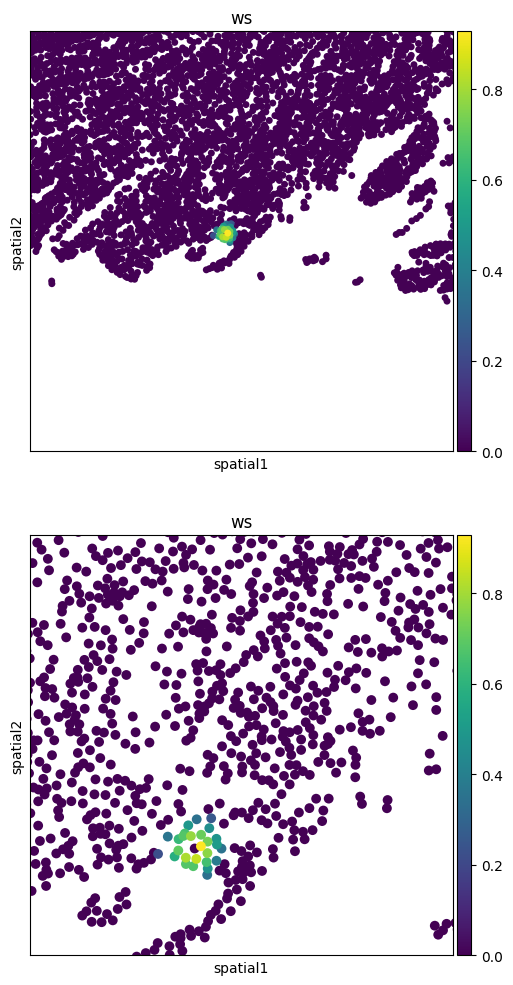

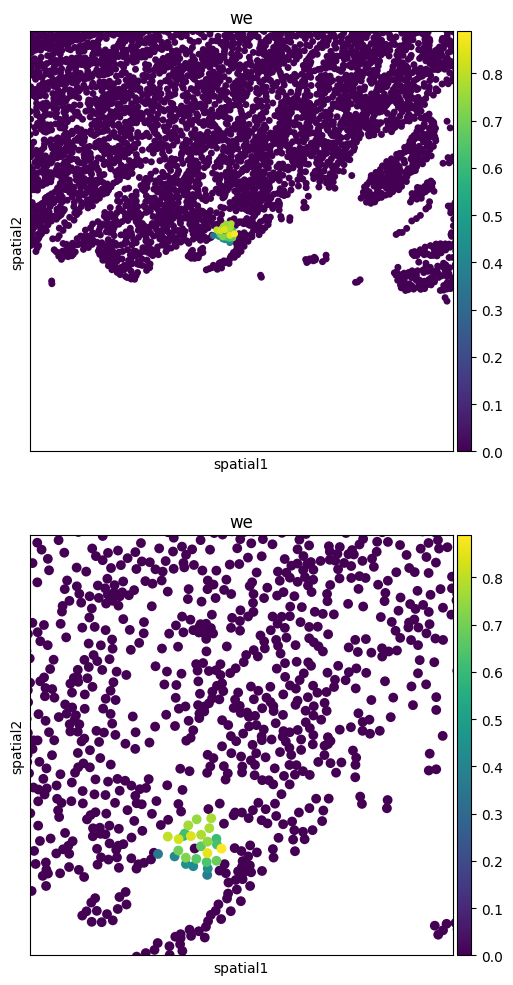

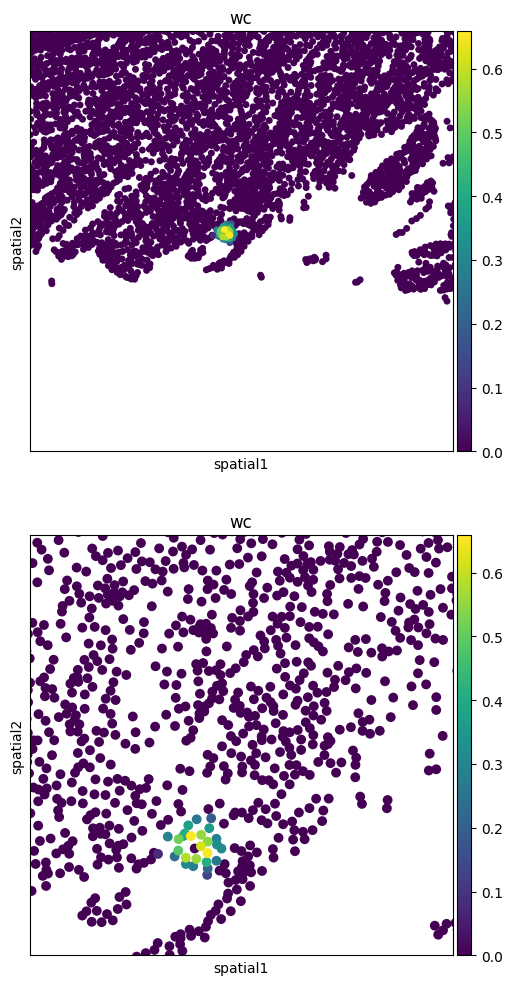

In [192]:


adata_ 
adata = adata_[adata_.obs['sample']=='cryo7D_S1']
idx = adata.obs_names
pos = adata_.obs_names.get_indexer(idx)
for weight in ['ws','we','wc']:
    adata.obsm[weight] = adata_.obsm[weight][pos][:, pos]
    i = 1555
    print(len(adata),adata.obsm[weight].shape)
    adata.obs[weight] = adata.obsm[weight].todense()[:,i].ravel().T

    fig,axes = get_figs(2,vert=True)
    ax = axes[0]
    space_plot(adata,weight,ax=ax,s=100)
    ax.get_xlim(),ax.get_ylim()
    ax.set_xlim(1500,3000),ax.set_ylim(0,1500)
    ax = axes[1]
    space_plot(adata,weight,ax=ax,s=200)
    ax.get_xlim(),ax.get_ylim()
    ax.set_xlim(2000,2500),ax.set_ylim(650,1150)
    # ax = axes[2]
    # space_plot(adata,'main_cell_type',ax=ax,s=200)
    # ax.get_xlim(),ax.get_ylim()
    # ax.set_xlim(2000,2500),ax.set_ylim(650,1150)